# RANDOM FOREST (CLASSIFICATION)

In [1]:
# IMPORTING LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as mlt
import warnings
warnings.filterwarnings("ignore")

In [2]:
#LOADING DATASET
from sklearn.datasets import load_breast_cancer
data=load_breast_cancer()
data

{'data': array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
         1.189e-01],
        [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
         8.902e-02],
        [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
         8.758e-02],
        ...,
        [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
         7.820e-02],
        [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
         1.240e-01],
        [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
         7.039e-02]], shape=(569, 30)),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
        1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
        1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1,

In [4]:
#CONVERTING DATA INTO A DATA FRAME
df=pd.DataFrame(np.c_[data.data,data.target],
               columns=[list(data.feature_names)+["target"]])
df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0.0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0.0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0.0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0.0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0.0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0.0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0.0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0.0


In [5]:
# RANDOM FOREST (CLASSIFICATION)
# STEP 1: ASSIGNING VARIABLES(INDEPENDENT/DEPENDENT)

# INDEPENDENT VARIABLE
x=df.drop("target",axis=1)

# DEPENDENT VARIABLE
y=df[["target"]]

In [8]:
# STEP 2:IMPORT TRAIN TEST SPLIT
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test,=train_test_split(x,y,test_size=0.3,random_state=42)

In [9]:
print("Original size : ",df.shape)
print("x_train size : ",x_train.shape)
print("x_test size : ",x_test.shape)
print("y_train size : ",y_train.shape)
print("y_test size : ",y_test.shape)

Original size :  (569, 31)
x_train size :  (398, 30)
x_test size :  (171, 30)
y_train size :  (398, 1)
y_test size :  (171, 1)


In [10]:
# STEP 3: APPLY RANDOM FOREST CLASSIFICATION
from sklearn.ensemble import RandomForestClassifier
classifier=RandomForestClassifier(n_estimators=5)
classifier

,n_estimators,5
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [12]:
# STEP 4 :FIT TO DATA
# Use only train(x_train,y_train)
classifier.fit(x_train,y_train)

,n_estimators,5
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [14]:
# CHECK ACCURACY
classifier.score(x_test,y_test)

0.9649122807017544

In [15]:
# PREDICTION OF NEW DATA
# IMPORT NUMPY FIRST(DATA MUST IN ARRAY FORM)
patient=np.array([[21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,
                   26.40,26.40,26.40,26.40,26.40,26.40,26.40,26.40,26.40,26.40,
                   26.40,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115]])
patient

array([[2.156e+01, 2.239e+01, 1.420e+02, 1.479e+03, 1.110e-01, 1.159e-01,
        2.439e-01, 1.389e-01, 1.726e-01, 5.623e-02, 2.640e+01, 2.640e+01,
        2.640e+01, 2.640e+01, 2.640e+01, 2.640e+01, 2.640e+01, 2.640e+01,
        2.640e+01, 2.640e+01, 2.640e+01, 2.640e+01, 1.661e+02, 2.027e+03,
        1.410e-01, 2.113e-01, 4.107e-01, 2.216e-01, 2.060e-01, 7.115e-02]])

In [16]:
prediction=classifier.predict(patient)
if (prediction[0]==0):
    print("Patient has Malignent tumor")
else:
    print("Patient has Benign tumor")

Patient has Malignent tumor


In [17]:
# EVALUATE MODEL
from sklearn.metrics import(accuracy_score,classification_report,confusion_matrix,ConfusionMatrixDisplay)

In [19]:
y_pred=classifier.predict(x_test)
print("accuracy:",accuracy_score(y_test,y_pred))
print("\nclassification Report:\n",classification_report(y_test,y_pred))

accuracy: 0.9649122807017544

classification Report:
               precision    recall  f1-score   support

         0.0       0.93      0.98      0.95        63
         1.0       0.99      0.95      0.97       108

    accuracy                           0.96       171
   macro avg       0.96      0.97      0.96       171
weighted avg       0.97      0.96      0.97       171



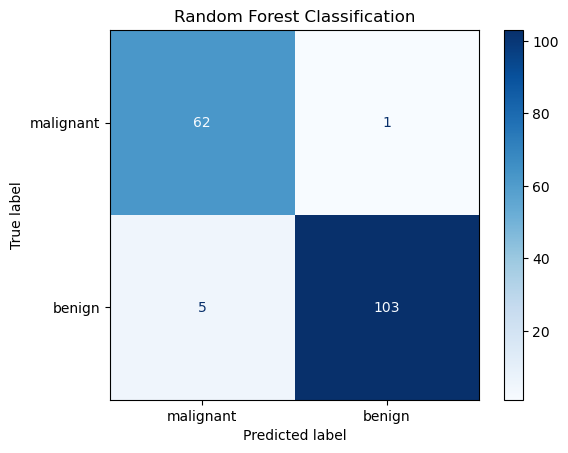

In [21]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)
disp.plot(cmap="Blues")
mlt.title("Random Forest Classification")
mlt.show()